## Librerias 

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import export_text
from sklearn.tree import plot_tree
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, KFold
from scipy.stats import randint
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
from scipy.stats import randint, uniform
from sklearn.ensemble import (BaggingRegressor, RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor)

## Cargar el csv y ver su informacion

In [17]:
from cleaning import load_data

df = load_data("Data/hour.csv")
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


# Mapa de calor para ver la relacion entre variables

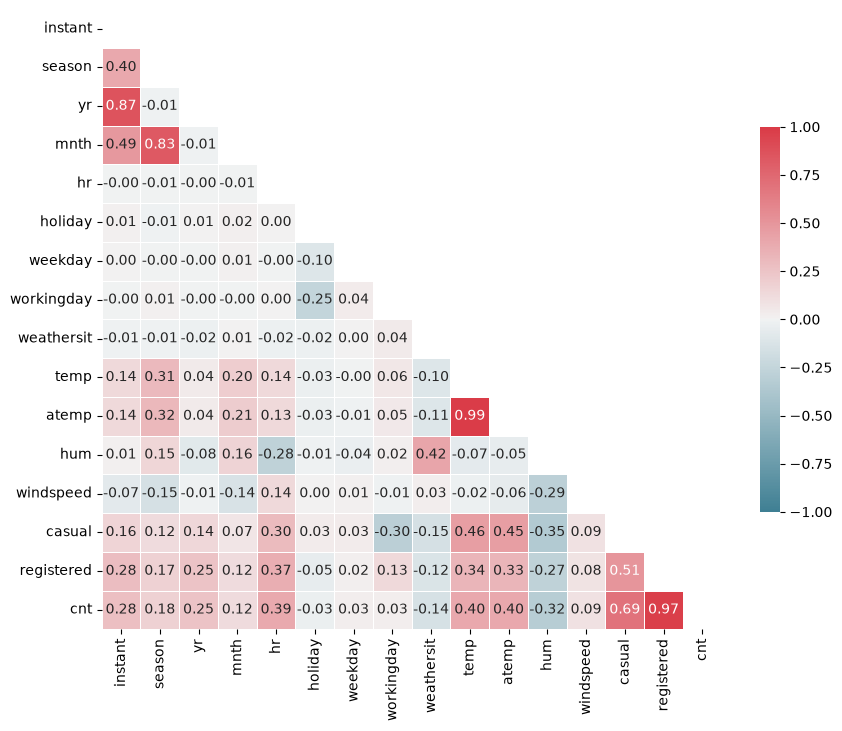

In [35]:
corr = df.select_dtypes(include='number').corr()


mask = np.triu(np.ones_like(corr, dtype=bool))

f, ax = plt.subplots(figsize=(10, 10))
cmap = sns.diverging_palette(220, 10, as_cmap=True)

sns.heatmap(corr, mask=mask, cmap=cmap, vmin=-1, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5},
            annot=True, fmt=".2f")

plt.show()

# Limpiar columnas 'casual', 'registered', 'instant', 'dteday'

In [18]:
from cleaning import drop_leakage

df = drop_leakage(df)

# Se queda con las columnas a utilizar 'yr', 'mnth', 'hr', 'workingday', 'weathersit', 'temp', 'windspeed'

In [19]:
from cleaning import select_features
df = select_features(df)

# Crea un df con dummies

In [20]:
from cleaning import encode_dummies

df_norm = encode_dummies(df)

In [26]:
df_norm = df_norm.drop(columns=['cnt'])

In [ ]:
features_norm = df_norm

# Separa el target y el features

In [21]:
from cleaning import split_xy

features, target = split_xy(df)

# Se Realiza el train test 

In [36]:
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.20, random_state=0)

## Probando linea de regresion

In [41]:
lin_reg = LinearRegression()

In [43]:
lin_reg.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 84.62, 4.02, 8.88,...,-29.44,302.64,104.33]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['yr','mnth','hr',...,'weathersit','temp','windspeed']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-115.6
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


## MAE:Mide cuánto se equivoca tu modelo, de media, respecto a los valores reales, sin tener en cuenta si el error es positivo o negativo.

## RMSE (Root Mean Squared Error)También mide cuánto se equivoca tu modelo, pero penaliza más los errores grandes.

## R² Score (Coeficiente de determinación)
## Mide cuánto mejor predice tu modelo los datos, en comparación con utilizar simplemente la media de los valores reales como predicción.

# Resultados de linea de regresion 

In [45]:
pred = lin_reg.predict(X_test)

print("MAE", mean_absolute_error(y_test, pred))
print("RMSE", np.sqrt(mean_squared_error(y_test, pred)))
print("R2 score", lin_reg.score(X_test, y_test))

MAE 108.65371359765416
RMSE 145.97114699514714
R2 score 0.3614579966782703


# Se utiliza KNN Regressor por que las columnas son numericas no categoricas

In [37]:
knn = KNeighborsRegressor(n_neighbors=4)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",4
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [38]:
y_pred = knn.predict(X_test)

# Resultado del KNN sin normalizar ni dummies

In [39]:
print("R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2: 0.8944604347929602
MAE: 36.18325661680092
RMSE: 59.34442629351024


## Resultado de por que en knn no se usa dummies para este proyecto. 

In [40]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def evaluar(cols, dummies, cv=kf):
    Xc = pd.get_dummies(df[cols], columns=dummies)
    modelo = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5))
    return cross_val_score(modelo, Xc, df['cnt'], cv=cv, scoring='r2').mean()

print("Actual:", evaluar(['season','yr','mnth','hr','weekday','workingday','weathersit','temp','windspeed'],
                         ['season','weekday','weathersit']))
print("Sin season:", evaluar(['yr','mnth','hr','weekday','workingday','weathersit','temp','windspeed'],
                             ['weekday','weathersit']))
print("Sin season ni weekday:", evaluar(['yr','mnth','hr','workingday','weathersit','temp','windspeed'],
                                        ['weathersit']))

Actual: 0.6420622327214676
Sin season: 0.6725465340635578
Sin season ni weekday: 0.7792458077113121


# Probando arbol de desicion 

In [46]:
tree = DecisionTreeRegressor(max_depth=10)

In [48]:
tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",10
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes 

# Resultado del arbol de desicion

In [50]:
pred = tree.predict(X_test)

print("MAE", mean_absolute_error(y_test, pred))
print("RMSE", np.sqrt(mean_squared_error(y_test, pred)))
print("R2 score", tree.score(X_test, y_test))

MAE 38.15539759035973
RMSE 61.330548928793036
R2 score 0.8872778839555981


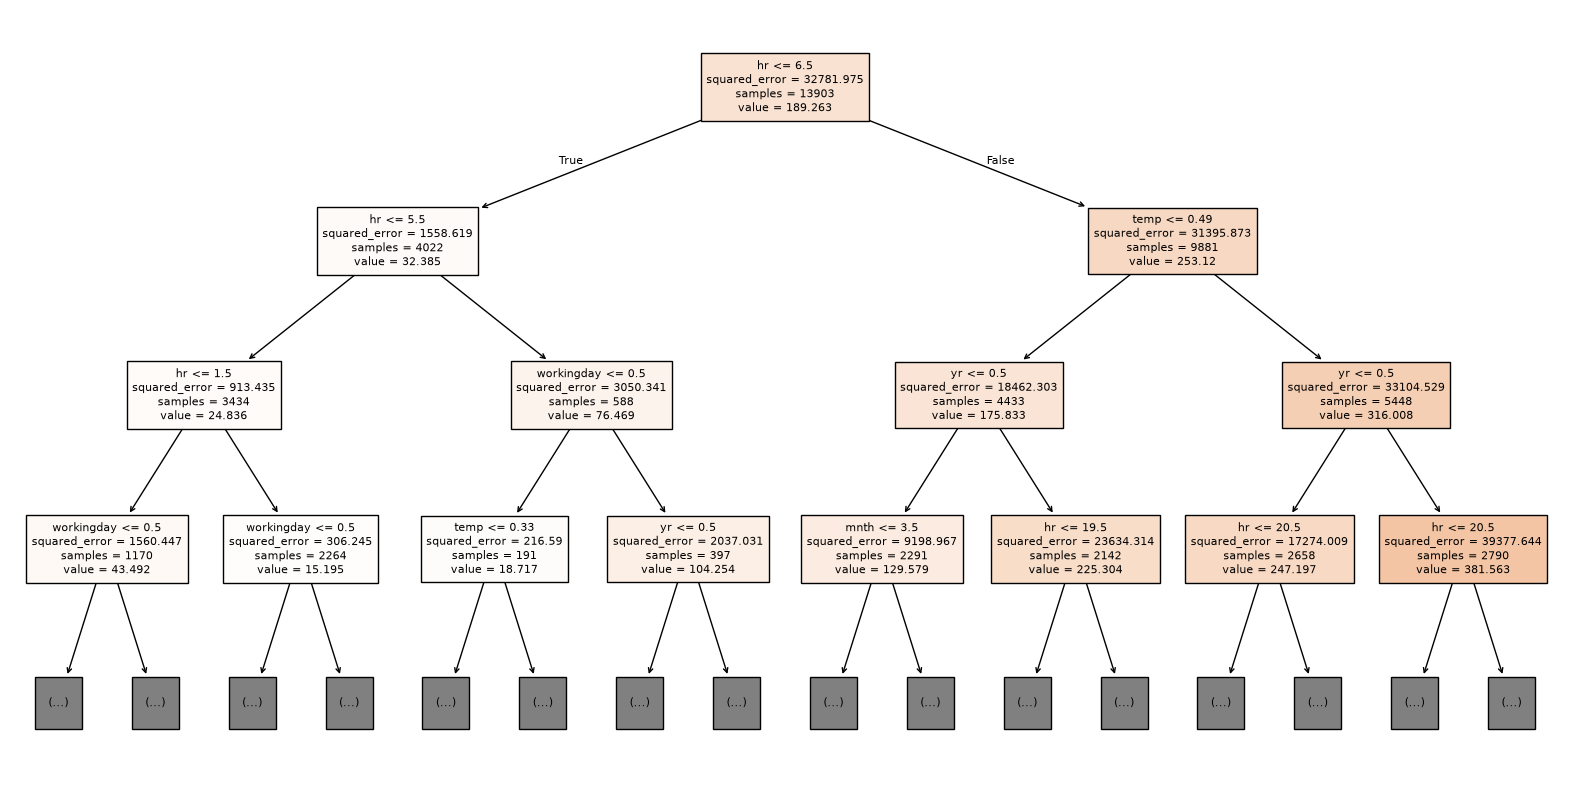

In [51]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
plot_tree(tree, feature_names=X_train.columns, filled=True, max_depth=3, fontsize=8)
plt.show()

# Probando con Bagging 

In [52]:
bagging_reg = BaggingRegressor(DecisionTreeRegressor(max_depth=20), 
                               n_estimators=100,
                               max_samples = 1000) 

In [54]:
bagging_reg.fit(X_train, y_train)

,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeRegressor`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeR...(max_depth=20)
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",100
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",1000
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


In [55]:
pred = bagging_reg.predict(X_test)

print("MAE", mean_absolute_error(pred, y_test))
print("RMSE",np.sqrt(mean_squared_error(y_test, pred)))
print("R2 score", bagging_reg.score(X_test, y_test))

MAE 38.04527617951669
RMSE 59.456457478166925
R2 score 0.8940615807220211


# Probando con pasting 

In [56]:
pasting_reg = BaggingRegressor(
    DecisionTreeRegressor(max_depth=20),
    n_estimators=100,      # número de árboles
    max_samples=1000,      # filas que ve cada árbol
    bootstrap=False,    
    random_state=42,
)

In [57]:
pasting_reg.fit(X_train, y_train)
pred = pasting_reg.predict(X_test)

# Resultado con Pasting

In [60]:
print("MAE", mean_absolute_error(pred, y_test))
print("RMSE",np.sqrt(mean_squared_error(y_test, pred)))
print("R2 score", pasting_reg.score(X_test, y_test))

MAE 37.82688832949751
RMSE 58.899595009142544
R2 score 0.8960367023729687


# Probando Randon Forest

In [61]:
forest = RandomForestRegressor(n_estimators=100,
                             max_depth=20)

In [62]:
forest.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number

# Resultado del Random Forest

In [64]:
pred = forest.predict(X_test)

print("MAE", mean_absolute_error(pred, y_test))
print("RMSE",np.sqrt(mean_squared_error(y_test, pred)))
print("R2 score", forest.score(X_test, y_test))

MAE 32.32261801803793
RMSE 53.5816139405915
R2 score 0.9139626528273606


# Probando con AdaBoost

In [ ]:
ada_reg = AdaBoostRegressor(DecisionTreeRegressor(max_depth=20), n_estimators=100)

In [66]:
ada_reg.fit(X_train, y_train)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.If ``None``, then the base estimator is:class:`~sklearn.tree.DecisionTreeRegressor` initialized with`max_depth=3`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeR...(max_depth=20)
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"learning_rate learning_rate: float, default=1.0Weight applied to each regressor at each boosting iteration. A higherlearning rate increases the contribution of each regressor. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"loss loss: {'linear', 'square', 'exponential'}, default='linear'The loss function to use when updating the weights after eachboosting iteration.",'linear'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.In addition, it controls the bootstrap of the weights used to train the`estimator` at each boosting iteration.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
Name,Type,Value
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeRegressor,DecisionTreeR...(max_depth=20)
estimator_errors_ estimator_errors_: ndarray of floatsRegression error for each estimator in the boosted ensemble.,"ndarray[float64](100,)","[0.03,0.03,0.02,...,0.22,0.2 ,0.22]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](100,)","[3.52,3.57,3.72,...,1.27,1.37,1.28]"
estimators_ estimators_: list of regressorsThe collection of fitted sub-estimators.,list,"[DecisionTreeR...te=1710908707), DecisionTreeR...te=1222888031), DecisionTreeR...te=1925213079), DecisionTreeR...te=1175207908), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](7,)","[0.04,0.06,0.33,...,0.03,0.46,0.04]"


In [67]:
pred = ada_reg.predict(X_test)

print("MAE", mean_absolute_error(pred, y_test))
print("RMSE",np.sqrt(mean_squared_error(y_test, pred)))
print("R2 score", ada_reg.score(X_test, y_test))

MAE 35.2718468111247
RMSE 55.12718442502501
R2 score 0.9089275430925848


# Probando con Gradient Boosting

In [ ]:
gb_reg = GradientBoostingRegressor(max_depth=20, n_estimators=100)

In [69]:
gb_reg.fit(X_train, y_train)

,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",20
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init i

# Resultado Gradient Boosting

In [70]:
pred = gb_reg.predict(X_test)

print("MAE", mean_absolute_error(pred, y_test))
print("RMSE",np.sqrt(mean_squared_error(y_test, pred)))
print("R2 score", gb_reg.score(X_test, y_test))

MAE 39.50883397825802
RMSE 65.03352781793454
R2 score 0.8732552275080386


# Resultado del Grid Search Con todos los modelos 

In [ ]:
busquedas = {
    "Bagging": (
        BaggingRegressor(DecisionTreeRegressor(), random_state=42),
        {"n_estimators": [50, 100], "max_samples": [1000, 5000, 10000],
         "estimator__max_depth": [10, 20]},
    ),

    "Pasting": (pasting_reg, param_grid_pasting),
    "Random Forest": (
        RandomForestRegressor(random_state=42),
        {"n_estimators": [100, 200], "max_depth": [10, 20, None], "min_samples_leaf": [1, 3, 5]},
    ),

    "AdaBoost": (
        AdaBoostRegressor(DecisionTreeRegressor(), random_state=42),
        {"n_estimators": [50, 100], "learning_rate": [0.1, 0.5, 1.0],
         "estimator__max_depth": [3, 6]},
    ),

    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=42),
        {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]},
    ),
}


           Modelo  R2 CV  R2 test  MAE test                                                                                       Mejores parámetros
Gradient Boosting 0.9242   0.9221      31.8                                              {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
          Bagging 0.9182   0.9173      32.0                                   {'estimator__max_depth': 20, 'max_samples': 5000, 'n_estimators': 100}
          Pasting 0.9165   0.9169      31.9 {'estimator__max_depth': 20, 'estimator__min_samples_leaf': 1, 'max_samples': 5000, 'n_estimators': 100}
    Random Forest 0.9157   0.9167      31.9                                            {'max_depth': 20, 'min_samples_leaf': 3, 'n_estimators': 200}
         AdaBoost 0.8384   0.8160      57.8                                    {'estimator__max_depth': 6, 'learning_rate': 1.0, 'n_estimators': 50}


# Ejecutando esta linea podemos ver el resultado del Grid Search con todos los modelos. Los mejores resultado para cada uno.

In [ ]:
filas = []
mejores = {}
for nombre, (modelo, rejilla) in busquedas.items():
    print("Entrenando", nombre)
    g = GridSearchCV(modelo, rejilla, cv=kf, scoring="r2", n_jobs=-1)
    g.fit(X_train, y_train)
    pred = g.best_estimator_.predict(X_test)
    mejores[nombre] = g.best_estimator_
    filas.append({
        "Modelo": nombre,
        "R2 CV": round(g.best_score_, 4),
        "R2 test": round(r2_score(y_test, pred), 4),
        "MAE test": round(mean_absolute_error(y_test, pred), 1),
        "Mejores parámetros": g.best_params_,
    })

print(pd.DataFrame(filas).sort_values("R2 test", ascending=False).to_string(index=False))

           Modelo  R2 CV  R2 test  MAE test                                                                                       Mejores parámetros
Gradient Boosting 0.9242   0.9221      31.8                                              {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
          Bagging 0.9182   0.9173      32.0                                   {'estimator__max_depth': 20, 'max_samples': 5000, 'n_estimators': 100}
          Pasting 0.9165   0.9169      31.9 {'estimator__max_depth': 20, 'estimator__min_samples_leaf': 1, 'max_samples': 5000, 'n_estimators': 100}
    Random Forest 0.9157   0.9167      31.9                                            {'max_depth': 20, 'min_samples_leaf': 3, 'n_estimators': 200}
         AdaBoost 0.8384   0.8160      57.8                                    {'estimator__max_depth': 6, 'learning_rate': 1.0, 'n_estimators': 50}


In [89]:
res_grid = pd.DataFrame(filas)
res_grid["Búsqueda"] = "Grid"

# Busquedas de los mejores parametros para Random Search con cada uno de los modelos 

In [86]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

busquedas_rs = {
    "Bagging": (
        BaggingRegressor(DecisionTreeRegressor(), random_state=42),
        {"n_estimators": randint(50, 200),
         "max_samples": randint(1000, 10000),
         "estimator__max_depth": randint(10, 50),
         "estimator__min_samples_leaf": randint(1, 10)},
    ),
    "Pasting": (
        BaggingRegressor(DecisionTreeRegressor(), bootstrap=False, random_state=42),
        {"n_estimators": randint(50, 200),
         "max_samples": randint(1000, 10000),
         "estimator__max_depth": randint(10, 50),
         "estimator__min_samples_leaf": randint(1, 10)},
    ),
    "Random Forest": (
        RandomForestRegressor(random_state=42),
        {"n_estimators": randint(100, 300),
         "max_depth": randint(5, 30),
         "min_samples_leaf": randint(1, 10)},
    ),
    "AdaBoost": (
        AdaBoostRegressor(DecisionTreeRegressor(), random_state=42),
        {"n_estimators": randint(50, 200),
         "learning_rate": uniform(0.05, 0.95),
         "estimator__max_depth": randint(2, 8)},
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=42),
        {"n_estimators": randint(100, 300),
         "learning_rate": uniform(0.02, 0.18),
         "max_depth": randint(2, 7)},
    ),
}


# Resultado de la busqueda de para cada uno de los modelos

In [88]:
filas = []
mejores_rs = {}
for nombre, (modelo, distribuciones) in busquedas_rs.items():
    print("Entrenando", nombre)
    r = RandomizedSearchCV(modelo, distribuciones, n_iter=10, cv=kf,
                           scoring="r2", n_jobs=-1, random_state=42)
    r.fit(X_train, y_train)
    pred = r.best_estimator_.predict(X_test)
    mejores_rs[nombre] = r.best_estimator_
    filas.append({
        "Modelo": nombre,
        "R2 CV": round(r.best_score_, 4),
        "R2 test": round(r2_score(y_test, pred), 4),
        "MAE test": round(mean_absolute_error(y_test, pred), 1),
        "Mejores parámetros": r.best_params_,
    })

print(pd.DataFrame(filas).sort_values("R2 test", ascending=False).to_string(index=False))

Entrenando Bagging
Entrenando Pasting
Entrenando Random Forest
Entrenando AdaBoost
Entrenando Gradient Boosting
           Modelo  R2 CV  R2 test  MAE test                                                                                       Mejores parámetros
Gradient Boosting 0.9253   0.9214      31.2                              {'learning_rate': 0.10266480055385609, 'max_depth': 6, 'n_estimators': 199}
          Bagging 0.9176   0.9169      32.1 {'estimator__max_depth': 30, 'estimator__min_samples_leaf': 1, 'max_samples': 5555, 'n_estimators': 107}
          Pasting 0.9153   0.9162      32.0 {'estimator__max_depth': 30, 'estimator__min_samples_leaf': 1, 'max_samples': 5555, 'n_estimators': 107}
    Random Forest 0.9128   0.9136      32.3                                            {'max_depth': 25, 'min_samples_leaf': 1, 'n_estimators': 157}
         AdaBoost 0.8639   0.8664      45.3                   {'estimator__max_depth': 7, 'learning_rate': 0.10359100007574525, 'n_estimators':

In [90]:
res_rand = pd.DataFrame(filas)
res_rand["Búsqueda"] = "Random"

In [91]:
pd.concat([res_grid, res_rand]).to_csv("Data/resultados_modelos.csv", index=False)